NOTE: Day 71-73 mein har metric ek fixed threshold (0.5) par nikla tha. ROC curve poore thresholds ko ek saath dikhata hai. Har threshold par do cheezein naapi jaati hain:

- TPR (Recall) = TP / (TP + FN): churners mein se kitne pakde
- FPR = FP / (FP + TN): active customers mein se kitnon ko galti se churn bola

Threshold 1 se 0 ki taraf le jao to dono badhte hain. Curve jitna upar-left ke paas, model utna behtar.

AUC curve ke neeche ka area hai (0 se 1):

- 0.5 = random guess (diagonal line)
- 1.0 = perfect
- < 0.5 = model ulta soch raha hai

AUC ka seedha matlab: agar ek asli churner aur ek asli active customer randomly chuno, to model ke hisaab se churner ka risk score zyada hone ki probability = AUC. Yaani AUC ranking quality naapta hai, kisi ek threshold ki performance nahi.

Aaj ka rule: Model chunne ka faisla CV ke out-of-fold (OOF) probabilities se hoga. Test set sirf confirmation hai. Threshold bhi CV se chuna jayega.

1. Setup (OOF probabilities dono models ke liye):

In [2]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_curve, roc_auc_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

X_train = pd.read_csv('../data/processed/X_train.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').squeeze()
X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv').squeeze()

models = {
    'Logistic Regression': joblib.load('models/logreg_pipeline.joblib'),
    'Decision Tree (tuned)': joblib.load('models/decision_tree_tuned.joblib'),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = {name: cross_val_predict(m, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
       for name, m in models.items()}
test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}

cross_val_predict har training customer ke liye aisi probability deta hai jo us customer ko dekhe bina bani thi. Isliye yeh imandaar estimate hai.

2. AUC ko khud verify karo (pairwise ranking):

In [3]:
scores = test_proba['Logistic Regression']
pos = scores[y_test.values == 1]
neg = scores[y_test.values == 0]

pairwise = (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()
print(f"Pairwise ranking probability: {pairwise:.4f}")
print(f"sklearn roc_auc_score       : {roc_auc_score(y_test, scores):.4f}")

Pairwise ranking probability: 0.8094
sklearn roc_auc_score       : 0.8094


Dono numbers same aane chahiye. Agar test set bahut bada ho aur memory error aaye, to pos aur neg ka random sample (jaise 1000-1000) lekar chalao.

3. Ek chhote example se curve banta kaise hai:

In [4]:
y_demo = np.array([1, 1, 0, 1, 0, 0, 0, 1])
s_demo = np.array([0.9, 0.8, 0.7, 0.6, 0.4, 0.3, 0.2, 0.1])

fpr, tpr, thr = roc_curve(y_demo, s_demo)
print(pd.DataFrame({'threshold': thr, 'FPR': fpr, 'TPR': tpr}).round(2))

   threshold   FPR   TPR
0        inf  0.00  0.00
1        0.9  0.00  0.25
2        0.8  0.00  0.50
3        0.7  0.25  0.50
4        0.6  0.25  0.75
5        0.2  1.00  0.75
6        0.1  1.00  1.00


Har row ek threshold ke liye (FPR, TPR) ka ek point hai. Sabko jod do to ROC curve ban gaya.

4. Dono models ka ROC curve (CV par, yeh decision wala chart hai):

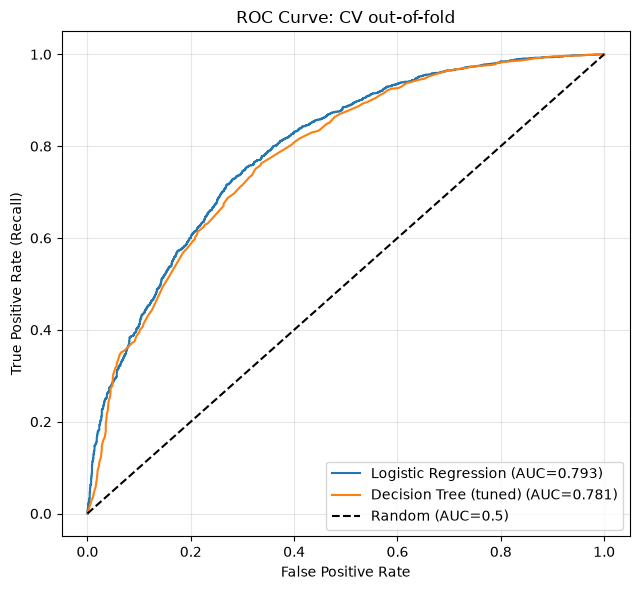

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_train, oof[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_train, oof[name]):.3f})")
ax.plot([0, 1], [0, 1], 'k--', label='Random (AUC=0.5)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC Curve: CV out-of-fold')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/roc_curve_cv.png', dpi=150)
plt.show()

- Jo curve doosre ke upar rahe, wo har trade-off par behtar hai.
- Agar curves beech mein cross karte hain, to behtar model is par depend karta hai ki tum kahan operate karte ho (kam FPR wala hissa ya zyada Recall wala hissa).
- Decision Tree ka curve seedhi, kam-point wali line (staircase) jaisa dikhega, kyunki tree ki probabilities leaf-wise coarse hoti hain aur unique values kam hoti hain. Yeh normal hai.

5. CV vs Test AUC aur uncertainty (bootstrap):

In [7]:
rng = np.random.default_rng(42)
n = len(y_test)
yt = y_test.values
boot = {name: [] for name in models}
boot_diff = []

for _ in range(1000):
    idx = rng.integers(0, n, n)
    if yt[idx].sum() in (0, n):
        continue
    a = {name: roc_auc_score(yt[idx], test_proba[name][idx]) for name in models}
    for name in models:
        boot[name].append(a[name])
    boot_diff.append(a['Decision Tree (tuned)'] - a['Logistic Regression'])

rows = []
for name in models:
    lo, hi = np.percentile(boot[name], [2.5, 97.5])
    rows.append({'model': name,
                 'CV AUC': roc_auc_score(y_train, oof[name]),
                 'Test AUC': roc_auc_score(y_test, test_proba[name]),
                 'Test 95% CI low': lo, 'Test 95% CI high': hi})
print(pd.DataFrame(rows).set_index('model').round(3))

lo, hi = np.percentile(boot_diff, [2.5, 97.5])
print(f"\nAUC fark (Tree - LogReg) 95% CI: {lo:.3f} to {hi:.3f}")
print("Fark clear hai" if (lo > 0 or hi < 0) else "Interval 0 ko cover karta hai: dono ko barabar maano")

                       CV AUC  Test AUC  Test 95% CI low  Test 95% CI high
model                                                                     
Logistic Regression     0.793     0.809            0.783             0.836
Decision Tree (tuned)   0.781     0.807            0.781             0.834

AUC fark (Tree - LogReg) 95% CI: -0.016 to 0.011
Interval 0 ko cover karta hai: dono ko barabar maano


CV aur Test AUC kaafi paas hone chahiye (Day 70 ka stability check).

6. Baseline aur leakage sanity check:

In [8]:
dummy = DummyClassifier(strategy='prior').fit(X_train, y_train)
print("Dummy AUC:", round(roc_auc_score(y_test, dummy.predict_proba(X_test)[:, 1]), 3))   # 0.5 aana chahiye

print("""
Agar tumhare real model ka AUC 0.95-0.99+ aaye, to khush hone se pehle SHAK karo.
Day 62 ke leakage-free setup mein churn predict karna asli mein mushkil hai, aur 0.6-0.85 ke beech AUC aam hai.
Bahut ooncha AUC aksar leakage ka signal hota hai.
""")

Dummy AUC: 0.5

Agar tumhare real model ka AUC 0.95-0.99+ aaye, to khush hone se pehle SHAK karo.
Day 62 ke leakage-free setup mein churn predict karna asli mein mushkil hai, aur 0.6-0.85 ke beech AUC aam hai.
Bahut ooncha AUC aksar leakage ka signal hota hai.



7. Operating point chunna: Youden’s J (CV se, test par ek baar):

In [9]:
fpr, tpr, thr = roc_curve(y_train, oof['Logistic Regression'])
j = tpr - fpr
best_t = thr[j.argmax()]
print(f"Youden's J best threshold (CV): {best_t:.3f}  -> TPR {tpr[j.argmax()]:.3f}, FPR {fpr[j.argmax()]:.3f}")

p = test_proba['Logistic Regression']
for label, t in [('default 0.5', 0.5), (f'Youden {best_t:.2f}', best_t)]:
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{label}: recall {tp/(tp+fn):.3f}, FPR {fp/(fp+tn):.3f}, flagged {pred.sum()}")

Youden's J best threshold (CV): 0.494  -> TPR 0.728, FPR 0.280
default 0.5: recall 0.739, FPR 0.255, flagged 559
Youden 0.49: recall 0.753, FPR 0.257, flagged 568


Youden’s J = TPR - FPR. Yeh wo point hai jahan curve diagonal se sabse door hai. Yeh sirf ek reasonable default hai. Business ke asli costs (Day 73 section 12) ko ignore karta hai, isliye wahi threshold final nahi hai.

8. ROC par apne operating points mark karo:

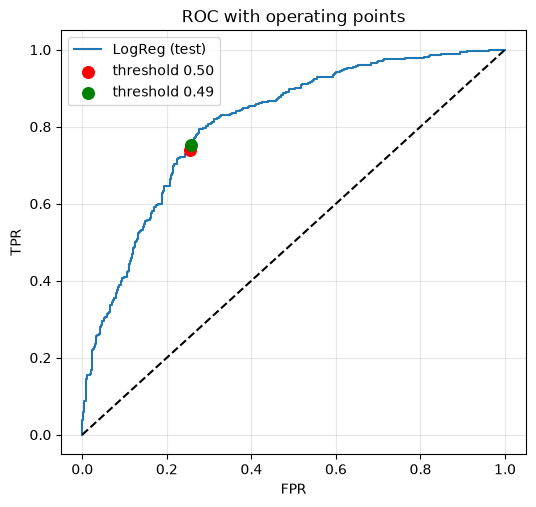

In [10]:
fpr_t, tpr_t, _ = roc_curve(y_test, test_proba['Logistic Regression'])
plt.figure(figsize=(6, 5.5))
plt.plot(fpr_t, tpr_t, label='LogReg (test)')
plt.plot([0, 1], [0, 1], 'k--')

for t, color in [(0.5, 'red'), (best_t, 'green')]:
    pred = (test_proba['Logistic Regression'] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    plt.scatter(fp / (fp + tn), tp / (tp + fn), color=color, s=70, zorder=3, label=f'threshold {t:.2f}')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC with operating points')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Ek model ka ek hi ROC curve hota hai, lekin threshold badalne se tum us curve par alag-alag points par pahunchte ho.

9. ROC-AUC ki limitation, aur PR curve (imbalanced data ke liye):

Churn prevalence (train): 0.566


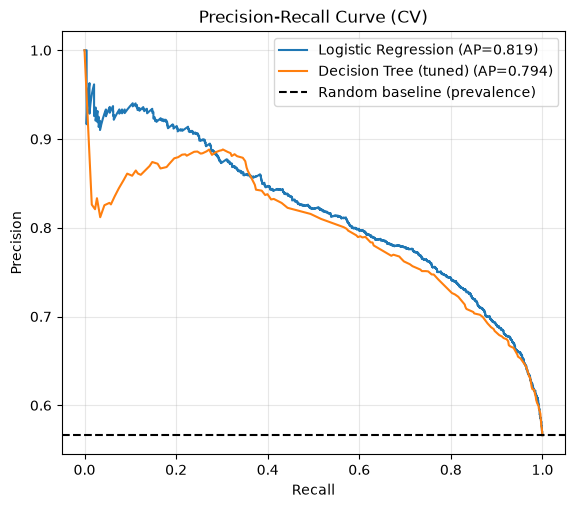

In [11]:
print(f"Churn prevalence (train): {y_train.mean():.3f}")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name in models:
    prec, rec, _ = precision_recall_curve(y_train, oof[name])
    ap = average_precision_score(y_train, oof[name])
    ax.plot(rec, prec, label=f"{name} (AP={ap:.3f})")
ax.axhline(y_train.mean(), color='k', linestyle='--', label='Random baseline (prevalence)')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve (CV)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Kab PR curve behtar hai: jab positive class bahut chhoti ho (jaise 5% churn), to FPR ka denominator bahut bada hota hai aur ROC-AUC zyada accha dikh sakta hai jabki precision kharab ho. Average Precision (AP) prevalence se compare hota hai (random model ka AP ≈ prevalence). Agar tumhara imbalance mild hai (jaise 60/40), to dono curves lagbhag same kahani batayenge.

10. Accuracy, F1 aur AUC mein farak ek line mein:

In [12]:
print("""
Accuracy / Precision / Recall / F1 : ek fixed threshold par model ka naap
ROC-AUC                            : threshold-free ranking quality (positive class ke hisaab se balanced)
Average Precision                  : imbalanced data mein precision-recall ka threshold-free naap
AUC bata sakta hai 'model churners ko upar rank karta hai', par yeh nahi ki 0.5 threshold par kitne sahi flag honge.
""")


Accuracy / Precision / Recall / F1 : ek fixed threshold par model ka naap
ROC-AUC                            : threshold-free ranking quality (positive class ke hisaab se balanced)
Average Precision                  : imbalanced data mein precision-recall ka threshold-free naap
AUC bata sakta hai 'model churners ko upar rank karta hai', par yeh nahi ki 0.5 threshold par kitne sahi flag honge.



11. Probability ki quality (calibration, optional jhalak):

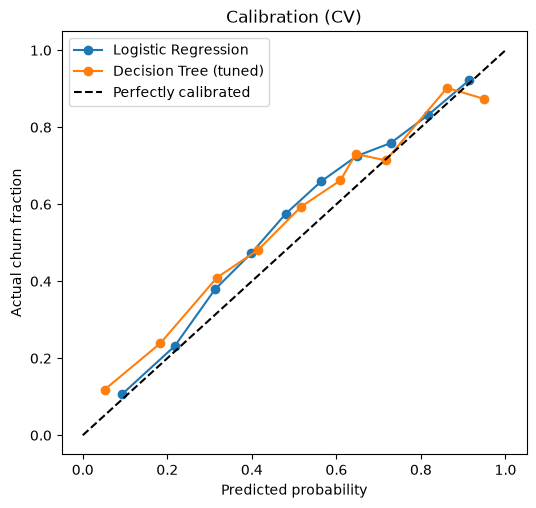

In [13]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(6, 5.5))
for name in models:
    frac_pos, mean_pred = calibration_curve(y_train, oof[name], n_bins=10, strategy='quantile')
    plt.plot(mean_pred, frac_pos, marker='o', label=name)
plt.plot([0, 1], [0, 1], 'k--', label='Perfectly calibrated')
plt.xlabel('Predicted probability')
plt.ylabel('Actual churn fraction')
plt.title('Calibration (CV)')
plt.legend()
plt.show()

AUC sirf ranking dekhta hai. Agar class_weight='balanced' ya SMOTE use kiya hai, to predicted probabilities sahi % nahi dikhati (wo inflate hoti hain), bas ranking achhi hoti hai. Isliye agar business ko “is customer ke churn ki 70% probability hai” jaisa bolna ho, to calibration alag se karni padegi. Ranking ke liye (top-K ko target karna) yeh zaroori nahi.


practice questions:

1. roc_auc_score ko class-wise region par alag-alag nikaalo (Region_* dummy columns se UK vs non-UK). Kya model kisi group par kaafi kamzor hai? Is se fairness aur robustness ka idea milta hai.

In [14]:
# Maan lete hain X_test mein 'Region_UK' ya similar column hai
# Agar dummy columns hain, toh hum unke base par subset bana sakte hain

region_col = 'Region_UK' if 'Region_UK' in X_test.columns else None

if region_col:
    for val in [0, 1]:
        mask = (X_test[region_col] == val)
        if mask.sum() > 10: # minimum samples check
            sub_y = y_test[mask]
            sub_proba = test_proba['Logistic Regression'][mask]
            auc_sub = roc_auc_score(sub_y, sub_proba)
            region_name = "UK" if val == 1 else "Rest of World"
            print(f"AUC for {region_name}: {auc_sub:.3f} (samples: {mask.sum()})")
else:
    print("Region columns not found in X_test. Check column names.")

AUC for Rest of World: 0.880 (samples: 85)
AUC for UK: 0.803 (samples: 972)


Business / Fairness Insight:
- Agar ek region par AUC 0.78 aaye aur doosre par 0.55, toh iska matlab hai ki model doosre region ke patterns ko theek se samajh nahi pa raha hai (ya wahan data kam tha).
- Aise checks Model Fairness aur Robustness ke liye bohot zaroori hote hain taaki pata chale ki model kisi ek demographic ya region ke sath unfair ya inaccurate toh nahi ho raha.

2. Agar Day 64C mein SMOTE use kiya tha, to baseline LogReg (bina SMOTE) ka AUC aur AP bhi nikaalo. SMOTE/class_weight ne ranking (AUC) badli ya sirf threshold-wala behaviour badla?

In [15]:
# Agar aapke paas bina class_weight wala model saved hai:
# model_plain = joblib.load('models/logreg_plain.joblib')
# proba_plain = model_plain.predict_proba(X_test)[:, 1]
# print("Plain LogReg AUC:", roc_auc_score(y_test, proba_plain))
# print("Tuned/SMOTE LogReg AUC:", roc_auc_score(y_test, test_proba['Logistic Regression']))

Core Concept :
- AUC (ROC-AUC) aur AP (Average Precision) ranking metrics hain.
- Jab aap class_weight='balanced' ya SMOTE use karte hain, toh model ki probabilities ki calibration (exact percentage values) badal jaati hain, lekin unka aapas ka order (ranking) lagbhag wahi rehta hai.
- Isliye, SMOTE ya class_weight lagane se AUC/AP mein bahut bada farak nahi padta (thoda-bohot upar-neeche ho sakta hai). Asli farak threshold-dependent metrics (jaise default 0.5 par Precision, Recall, aur F1) par padta hai kyunki model zyada churners ko flag karna shuru kar deta hai.

3. Apne shabdon mein likho: AUC 0.5 aur 0.8 ka matlab ek manager ko bina jargon ke samjhao.

Agar aapko apne manager ko AUC ka matlab bina kisi technical term (jaise FPR, TPR, ya probability curve) ke samjhana hai, toh aap yeh analogy de sakte hain:

"Sir/Ma'am, maankar chaliye ki humare paas 100 aise customers hain jo sach mein company chhod kar chale gaye (Churners) aur 100 aise customers hain jo active hain."

- AUC = 0.5 (Random / Tukka):
    - Agar humara model ek coin toss (sikha uchhalne) jitna kharab ya random hai, toh iska AUC 0.5 hoga. Iska matlab hai ki model ko koi idea nahi hai—woh kisi bhi active customer ko risk zone mein daal sakta hai aur churner ko chhod sakta hai. Jaise andhere mein teer chalana.

- AUC = 0.8 (Behtareen Ranking):
    - Agar humare model ka AUC 0.8 hai, toh iska matlab yeh hai ki agar hum ek asli churner aur ek active customer ko aapas mein randomly khada karein, toh 80% baar humara model yeh sahi pehchan lega ki kis customer par khatra zyada hai.
    - Yeh model ko ek "Smart Risk Ranker" banata hai, jo sabse zyada khatre wale logo ko list mein sabse upar rakh deta hai taaki hum apna discount budget sahi jagah use kar sakein.